In [1]:
%pip install gensim matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install scikit-learn
import sys
print(sys.version)

from gensim.models import Word2Vec
print("Gensim working!")

Note: you may need to restart the kernel to use updated packages.
3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Gensim working!


In [4]:
# Install/import the required libraries
# If gensim is not installed, run in Terminal:
# python -m pip install gensim scikit-learn matplotlib pandas

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from gensim.models import Word2Vec
from sklearn.manifold import TSNE

print("Libraries imported successfully.")

Libraries imported successfully.


In [5]:
corpus = [
    "king queen prince princess royal family palace",
    "king rules the kingdom and queen rules the palace",
    "prince and princess live in the royal palace",
    "man woman boy girl person family",
    "men and women work together in the organization",
    "boys and girls learn together at school",
    "teacher student school education learning",
    "teachers help students learn new concepts",
    "students study computer science and artificial intelligence",
    "computer science includes programming algorithms and data",
    "python programming is useful for artificial intelligence",
    "machine learning and deep learning are areas of artificial intelligence",
    "deep learning uses neural networks to learn patterns",
    "technology companies develop software and artificial intelligence",
    "software engineers write programs using python and other languages",
    "india has cities such as chennai bengaluru and mumbai",
    "chennai is a city in india",
    "bengaluru is a technology city in india",
    "mumbai is a large city in india",
    "paris is a city in france",
    "france is a country in europe",
    "india and france have cities and universities",
    "students visit universities to learn and study",
    "teachers and students work together on projects",
    "researchers develop new technology using machine learning"
]

print("Number of sentences:", len(corpus))

Number of sentences: 25


In [6]:
def preprocess(sentence):
    sentence = sentence.lower()
    sentence = re.sub(r"[^a-z\s]", "", sentence)
    return sentence.split()

tokenized_corpus = [preprocess(sentence) for sentence in corpus]

print("Original sentence:")
print(corpus[0])

print("\nTokenized sentence:")
print(tokenized_corpus[0])

Original sentence:
king queen prince princess royal family palace

Tokenized sentence:
['king', 'queen', 'prince', 'princess', 'royal', 'family', 'palace']


In [7]:
model = Word2Vec(
    sentences=tokenized_corpus,
    vector_size=50,
    window=3,
    min_count=1,
    workers=1,
    sg=1,
    epochs=200,
    seed=42
)

print("Word2Vec model trained successfully.")
print("Vocabulary size:", len(model.wv))

Word2Vec model trained successfully.
Vocabulary size: 91


In [8]:
word = "king"

print(f"Vector for '{word}':")
print(model.wv[word])

print("\nVector dimensions:", len(model.wv[word]))

Vector for 'king':
[ 0.03137549 -0.13162485 -0.08785322 -0.09379014  0.04166127  0.1108437
 -0.00478594  0.16091397 -0.27017927 -0.00485723 -0.18179673  0.2951099
 -0.1830717   0.41184866  0.10421317 -0.03745939  0.00672599 -0.23970573
  0.02062048 -0.09965947  0.03028517  0.06026147  0.0804796   0.08292677
  0.38040727  0.03009468  0.06207839  0.04335082 -0.15955742  0.04432551
  0.05354995 -0.11207322 -0.10463066  0.12849404 -0.00242252 -0.16669108
  0.03826926 -0.48750776 -0.03573011  0.13959426 -0.11091258  0.10448492
  0.39414364 -0.2650393   0.02853861  0.07439867 -0.04554377  0.42293793
  0.19698732 -0.19554643]

Vector dimensions: 50


In [9]:
def show_similar(word, topn=5):
    if word in model.wv:
        return pd.DataFrame(
            model.wv.most_similar(word, topn=topn),
            columns=["Word", "Similarity"]
        )
    else:
        print(f"'{word}' is not in the vocabulary.")

show_similar("king")

,Word,Similarity
0,palace,0.996149
1,the,0.995840
2,queen,0.995533
3,prince,0.995305
4,princess,0.994859


In [10]:
result = model.wv.most_similar(
    positive=["king", "woman"],
    negative=["man"],
    topn=5
)

pd.DataFrame(result, columns=["Word", "Similarity"])

,Word,Similarity
0,the,0.993501
1,prince,0.992545
2,palace,0.992021
3,princess,0.991979
4,royal,0.990941


In [11]:
result = model.wv.most_similar(
    positive=["india", "paris"],
    negative=["france"],
    topn=5
)

pd.DataFrame(result, columns=["Word", "Similarity"])

,Word,Similarity
0,education,0.984142
1,school,0.982300
2,city,0.981631
3,men,0.981355
4,student,0.980957


In [12]:
pairs = [
    ("king", "queen"),
    ("teacher", "student"),
    ("computer", "programming"),
    ("machine", "learning"),
    ("india", "chennai"),
    ("india", "bengaluru")
]

similarity_results = []

for word1, word2 in pairs:
    similarity_results.append({
        "Word 1": word1,
        "Word 2": word2,
        "Cosine Similarity": model.wv.similarity(word1, word2)
    })

pd.DataFrame(similarity_results)

,Word 1,Word 2,Cosine Similarity
0,king,queen,0.995534
1,teacher,student,0.995356
2,computer,programming,0.994360
3,machine,learning,0.995566
4,india,chennai,0.995836
5,india,bengaluru,0.993678


In [13]:
selected_words = [
    "king", "queen", "prince", "princess",
    "man", "woman", "boy", "girl",
    "teacher", "student", "school", "education",
    "computer", "programming", "python",
    "machine", "learning", "deep", "technology",
    "india", "chennai", "bengaluru", "mumbai",
    "paris", "france"
]

selected_words = [word for word in selected_words if word in model.wv]
vectors = np.array([model.wv[word] for word in selected_words])

print("Words selected for visualization:", len(selected_words))
print("Original vector shape:", vectors.shape)

Words selected for visualization: 25
Original vector shape: (25, 50)


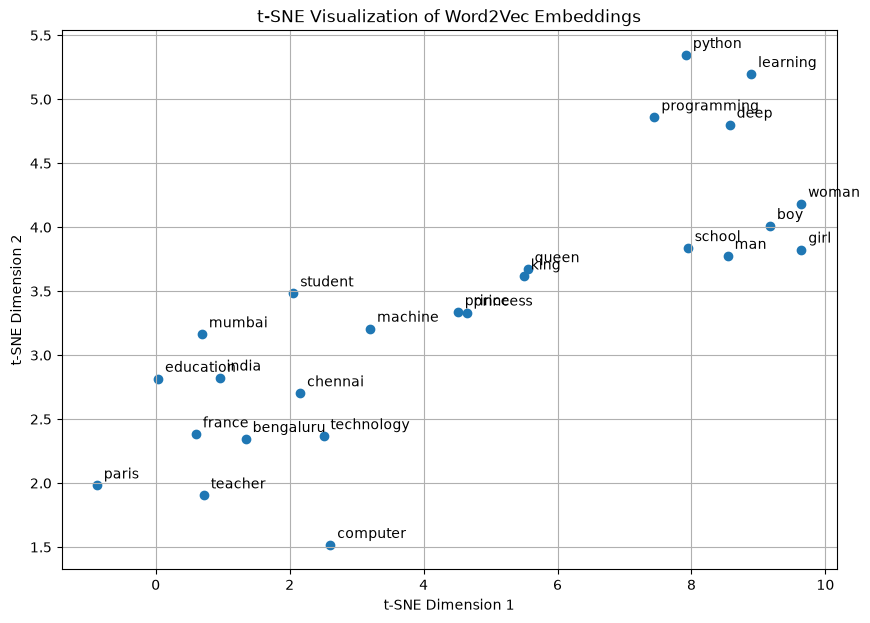

In [14]:
perplexity = min(10, len(selected_words) - 1)

tsne = TSNE(
    n_components=2,
    perplexity=perplexity,
    random_state=42,
    init="random",
    learning_rate="auto"
)

vectors_2d = tsne.fit_transform(vectors)

plt.figure(figsize=(10, 7))

plt.scatter(vectors_2d[:, 0], vectors_2d[:, 1])

for i, word in enumerate(selected_words):
    plt.annotate(
        word,
        (vectors_2d[i, 0], vectors_2d[i, 1]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("t-SNE Visualization of Word2Vec Embeddings")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.grid(True)
plt.show()